# 02. Eksploracyjna analiza danych (EDA)

**Krok procesu:** wejście do modelu baseline. Kurs zadaje trzy pytania do EDA: balans klas, liczba klas,
jakość danych. Odpowiadamy na nie na pełnym zbiorze adnotacji HaGRIDv2 (1,086,158 obrazów), nie na próbce.

Obrazów jeszcze nie pobraliśmy, więc sprawdzenie samych obrazów (rozdzielczość, rozmycie, ekspozycja) czeka
na podzbiór obrazów. Wszystko tutaj pochodzi z adnotacji: etykiety, ramki dłoni, landmarki i metadane.

In [1]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from features import extended_fingers, landmarks, normalise
from labels import DROPPED, FINGER_JOINTS, FINGERS, GESTURE_TO_COUNT, HAND_EDGES, NO_GESTURE

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
SPLITS = ["train", "val", "test"]
# Polskie nazwy palców tylko do wykresów i tabel.
FINGER_PL = {"thumb": "kciuk", "index": "wskazujący", "middle": "środkowy", "ring": "serdeczny", "pinky": "mały"}

images = pd.read_parquet("../data/interim/images.parquet")
hands = pd.read_parquet("../data/interim/hands.parquet")
hands["fingers"] = hands.label.map(GESTURE_TO_COUNT)

## 1. Liczba klas i balans gestów źródłowych

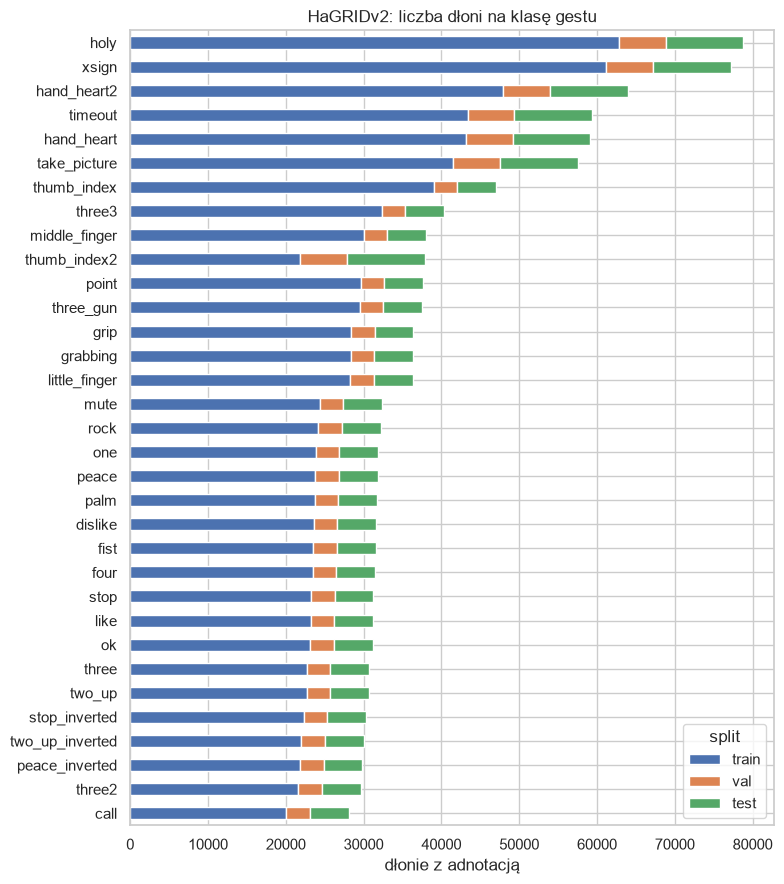

33 klas gestów, min 28,062, max 78,804, stosunek 2.81


In [2]:
per_gesture = hands[hands.label != NO_GESTURE].pivot_table(index="label", columns="split", values="image_id",
                                                            aggfunc="count")[SPLITS]
per_gesture["total"] = per_gesture.sum(axis=1)
per_gesture = per_gesture.sort_values("total")
ax = per_gesture[SPLITS].plot.barh(stacked=True, figsize=(8, 9))
ax.set(xlabel="dłonie z adnotacją", ylabel="", title="HaGRIDv2: liczba dłoni na klasę gestu")
plt.tight_layout(); plt.savefig(FIG / "eda_hands_per_gesture.png", dpi=150); plt.show()
print(f"{len(per_gesture)} klas gestów, min {per_gesture.total.min():,}, max {per_gesture.total.max():,}, "
      f"stosunek {per_gesture.total.max() / per_gesture.total.min():.2f}")

Gesty źródłowe są prawie zbalansowane. Niezbalansowanie pojawia się dopiero przez nasze mapowanie, co pokazujemy niżej.

## 2. Balans po zmapowaniu na liczbę palców

In [3]:
kept = hands[hands.fingers.notna()].copy()
kept["fingers"] = kept.fingers.astype(int)
counts = kept.pivot_table(index="fingers", columns="split", values="image_id", aggfunc="count")[SPLITS]
counts["udział %"] = (counts.sum(axis=1) / counts.sum().sum() * 100).round(1)
counts["gesty źródłowe"] = pd.Series(GESTURE_TO_COUNT).reset_index().groupby(0)["index"].count()
counts

split,train,val,test,udział %,gesty źródłowe
fingers,,,,,
0,23543,3000,5000,3.8,1
1,183107,21000,35003,28.7,7
2,195409,27002,45001,32.1,8
3,129399,15001,25001,20.4,5
4,23436,3000,5000,3.8,1
5,69278,9000,15000,11.2,3


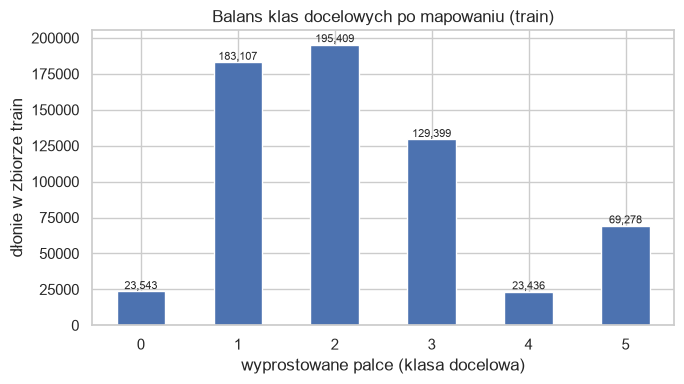

Stosunek klasy większościowej do mniejszościowej w train: 8.3x


In [4]:
ax = counts["train"].plot.bar(figsize=(7, 4), color=sns.color_palette()[0])
ax.set(xlabel="wyprostowane palce (klasa docelowa)", ylabel="dłonie w zbiorze train",
       title="Balans klas docelowych po mapowaniu (train)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom",
                fontsize=8)
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG / "eda_target_balance.png", dpi=150); plt.show()
ratio = counts["train"].max() / counts["train"].min()
print(f"Stosunek klasy większościowej do mniejszościowej w train: {ratio:.1f}x")

Klasa 1 ma siedem gestów źródłowych, a klasa 4 tylko jeden, więc zbiór po mapowaniu jest mocno niezbalansowany.
Val i test mają stałą liczbę dłoni na gest źródłowy (3,000 i 5,000), więc mają to samo niezbalansowanie.
Opcje na kolejne kroki to wagi klas w funkcji straty, undersampling dużych klas albo limit na każdy gest źródłowy.
Sama trafność (accuracy) będzie myląca, więc wszędzie podajemy macro F1 i macierz pomyłek.

## 3. Dłonie na obraz i dłonie `no_gesture`

In [5]:
images.n_hands.value_counts().sort_index().to_frame("obrazy")

,obrazy
n_hands,
1,668186
2,417970
3,1
4,1


In [6]:
two = images[images.n_hands == 2]
kept_two = two[~two.source_class.isin(DROPPED)]
with_relaxed = hands[hands.image_id.isin(kept_two.image_id) & (hands.label == NO_GESTURE)].image_id.nunique()
pd.Series({
    "udział dłoni z etykietą no_gesture": f"{(hands.label == NO_GESTURE).mean():.1%}",
    "obrazy z dwiema dłońmi z odrzuconych gestów (dwuręcznych)": f"{two.source_class.isin(DROPPED).sum():,}",
    "obrazy z dwiema dłońmi z zachowanych gestów": f"{len(kept_two):,}",
    "... w tym druga dłoń to no_gesture": f"{with_relaxed:,}",
}).to_frame("wartość")

,wartość
udział dłoni z etykietą no_gesture,13.5%
obrazy z dwiema dłońmi z odrzuconych gestów (dwuręcznych),"217,853"
obrazy z dwiema dłońmi z zachowanych gestów,"200,117"
... w tym druga dłoń to no_gesture,"181,174"


62% obrazów ma jedną dłoń. Około połowa obrazów z dwiema dłońmi pochodzi z gestów dwuręcznych, które i tak odrzucamy.
W zachowanych gestach druga dłoń to prawie zawsze rozluźniona dłoń `no_gesture`. Nie znamy jej liczby palców,
więc nie nadaje się na etykietę treningową do liczenia. Dla modelu na wycinkach dłoni to przydatny trudny przykład
negatywny, ale tylko jeśli dodamy klasę "to nie jest poza do liczenia". Ta decyzja jest otwarta.

## 4. Rozłączność podziałów: czy podziały są rozdzielone po osobach?

In [7]:
users = {s: set(images.user_id[images.split == s]) for s in SPLITS}
pd.DataFrame({"osoby": {s: len(u) for s, u in users.items()},
              "wspólne z train": {s: len(users[s] & users["train"]) if s != "train" else 0 for s in SPLITS}})

,osoby,wspólne z train
train,57656,0
val,4209,0
test,4114,2


Oficjalne podziały są w praktyce rozłączne po osobach (2 z 4,114 osób z test występują też w train, w val nikt).
Wynik na test mierzy więc uogólnianie na nowe osoby, a nie zapamiętane twarze czy pokoje. Zostajemy przy oficjalnych
podziałach.

## 5. Jakość danych

### 5a. Brakujące landmarki

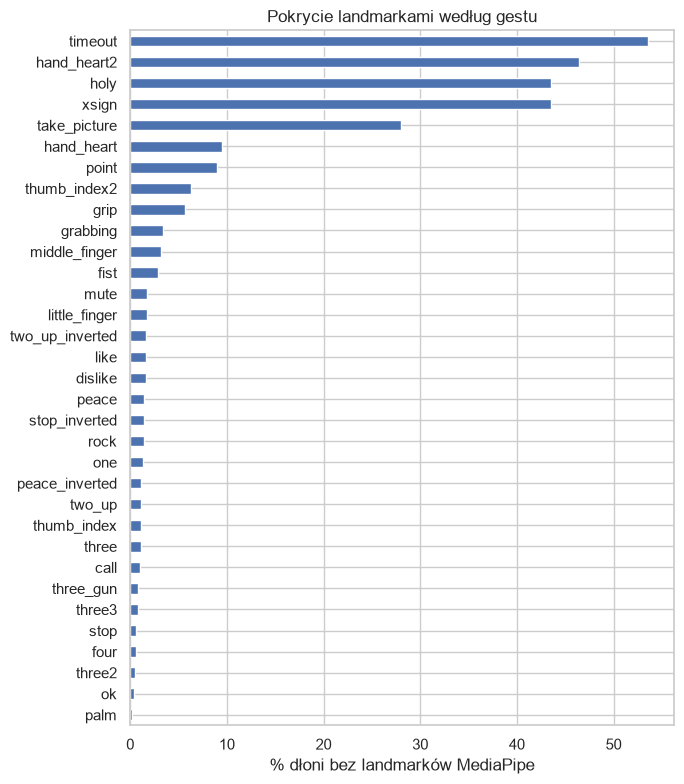

Łącznie brakuje: 1.9% zachowanych dłoni


In [8]:
miss = (1 - hands[hands.label != NO_GESTURE].groupby("label").has_landmarks.mean()).mul(100).sort_values()
ax = miss.plot.barh(figsize=(7, 8))
ax.set(xlabel="% dłoni bez landmarków MediaPipe", ylabel="", title="Pokrycie landmarkami według gestu")
plt.tight_layout(); plt.savefig(FIG / "eda_missing_landmarks.png", dpi=150); plt.show()
print(f"Łącznie brakuje: {(~kept.has_landmarks).mean() * 100:.1f}% zachowanych dłoni")

MediaPipe nie zadziałał na części dłoni. Ma to znaczenie z dwóch powodów. W modelu na punktach charakterystycznych
te dłonie po prostu przepadają. Dla aplikacji to ostrzeżenie. Jeśli MediaPipe gubi dłoń w zbiorze, zgubi ją też
na telefonie.

### 5b. Wielkość dłoni w kadrze

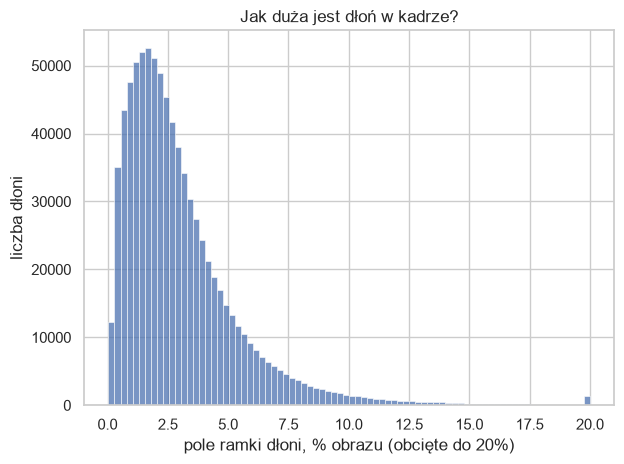

,pole ramki %
count,832180.00
mean,3.04
std,2.54
min,0.04
1%,0.25
5%,0.50
50%,2.41
95%,7.64
max,67.50


In [9]:
kept["box_area_pct"] = kept.bw * kept.bh * 100
ax = sns.histplot(kept.box_area_pct.clip(upper=20), bins=80)
ax.set(xlabel="pole ramki dłoni, % obrazu (obcięte do 20%)", ylabel="liczba dłoni",
       title="Jak duża jest dłoń w kadrze?")
plt.tight_layout(); plt.savefig(FIG / "eda_box_area.png", dpi=150); plt.show()
kept.box_area_pct.describe(percentiles=[0.01, 0.05, 0.5, 0.95]).round(2).to_frame("pole ramki %")

Dłonie na obrazach HaGRID są małe (mediana ramki to kilka % kadru). Podanie całego kadru do małej sieci CNN
zmarnowałoby większość pikseli, więc model obrazowy powinien działać na **wycinku dłoni**. To wymaga detektora
dłoni w aplikacji, np. MediaPipe albo małego detektora. To główna decyzja dotycząca przetwarzania wstępnego
w ścieżce obrazowej.

### 5c. Kontrola poprawności ramek

In [10]:
bad = pd.Series({
    "ramka poza obrazem": ((kept.bx < 0) | (kept.by < 0) | (kept.bx + kept.bw > 1.001) | (kept.by + kept.bh > 1.001)).sum(),
    "zerowy lub ujemny rozmiar": ((kept.bw <= 0) | (kept.bh <= 0)).sum(),
    "zduplikowane id obrazów": images.image_id.duplicated().sum(),
    "obrazy bez metadanych": images.age.isna().sum(),
})
bad.to_frame("liczba")

,liczba
ramka poza obrazem,27
zerowy lub ujemny rozmiar,0
zduplikowane id obrazów,0
obrazy bez metadanych,346


## 6. Kto jest w danych (sprawdzenie stronniczości)

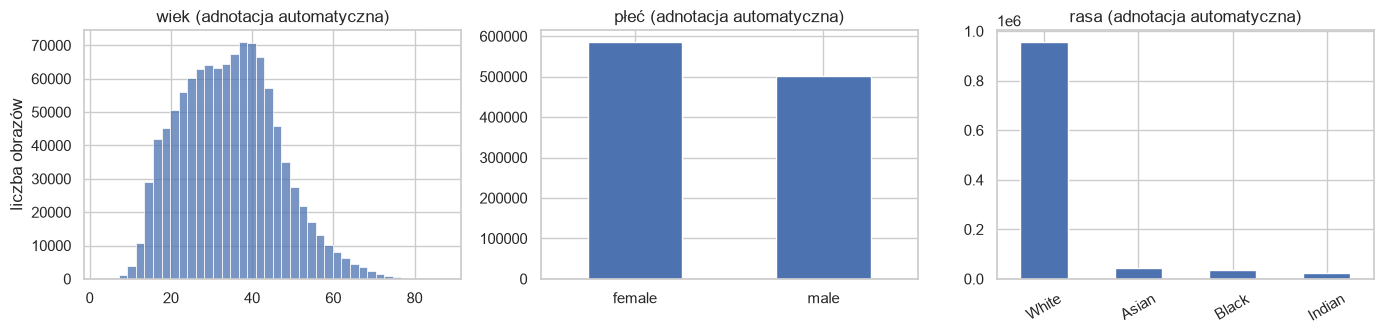

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(images.age.dropna(), bins=40, ax=axes[0]).set(title="wiek (adnotacja automatyczna)", xlabel="",
                                                           ylabel="liczba obrazów")
images.gender.value_counts().plot.bar(ax=axes[1], title="płeć (adnotacja automatyczna)", rot=0, xlabel="")
images.race.value_counts().plot.bar(ax=axes[2], title="rasa (adnotacja automatyczna)", rot=30, xlabel="")
plt.tight_layout(); plt.savefig(FIG / "eda_demographics.png", dpi=150); plt.show()

Metadane pochodzą z automatycznego anotatora, więc traktujemy je jako przybliżone. Pozwolą jednak później
sprawdzić, czy model działa tak samo dobrze dla różnych grup (np. kolor skóry w modelu obrazowym).

## 7. Weryfikacja mapowania gestu na liczbę palców

Mapowanie w `src/labels.py` to nasze własne założenie. Sprawdzamy je na dwa sposoby, bez obrazów:
1. Rysujemy losowe szkielety dłoni dla każdego gestu z landmarków, każdy palec innym kolorem.
2. Prosta reguła geometryczna (kąty w stawach) ocenia, które palce są wyprostowane. Potem porównujemy najczęstszy
   wynik z liczbą palców z mapowania.

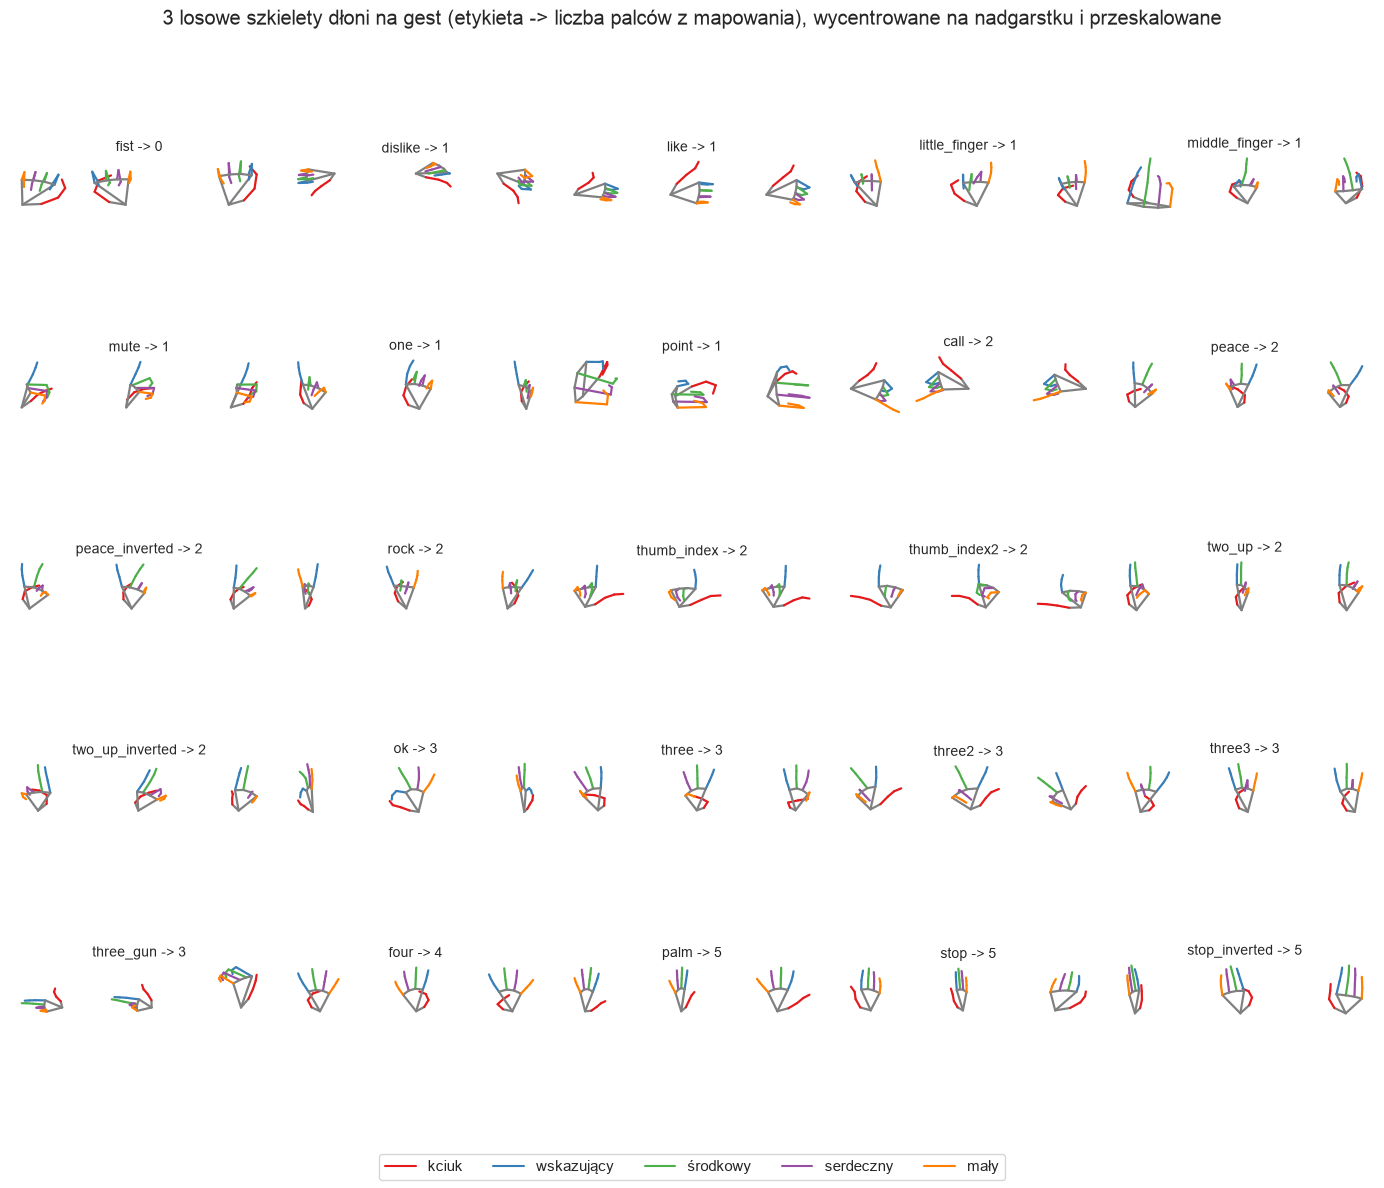

In [12]:
FINGER_COLOR = dict(zip(FINGERS, sns.color_palette("Set1", 5)))
# Krawędzie w obrębie jednego palca dostają kolor tego palca, krawędzie dłoni zostają szare.
EDGE_FINGER = {e: next((f for f, j in FINGER_JOINTS.items() if set(e) <= set(j)), None) for e in HAND_EDGES}
ordered = sorted(GESTURE_TO_COUNT, key=lambda g: (GESTURE_TO_COUNT[g], g))
with_lm = kept[kept.has_landmarks]
fig, axes = plt.subplots(5, 5, figsize=(14, 12))
for ax, g in zip(axes.flat, ordered):
    sample = normalise(landmarks(with_lm[with_lm.label == g].sample(3, random_state=1)))
    for k, lm in enumerate(sample):
        lm = lm + np.array([2.2 * k, 0])
        for e in HAND_EDGES:
            f = EDGE_FINGER[e]
            ax.plot(lm[list(e), 0], -lm[list(e), 1], lw=1.6, color=FINGER_COLOR[f] if f else "grey")
    ax.set_title(f"{g} -> {GESTURE_TO_COUNT[g]}", fontsize=10); ax.set_aspect("equal"); ax.axis("off")
fig.legend(handles=[plt.Line2D([], [], color=c, label=FINGER_PL[f]) for f, c in FINGER_COLOR.items()],
           loc="lower center", ncol=5)
plt.suptitle("3 losowe szkielety dłoni na gest (etykieta -> liczba palców z mapowania), "
             "wycentrowane na nadgarstku i przeskalowane")
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(FIG / "eda_skeletons_per_gesture.png", dpi=130); plt.show()

In [13]:
probe = with_lm.groupby("label").sample(3000, random_state=0)
ext = extended_fingers(landmarks(probe))
ext["label"] = probe.label.values
check = ext.groupby("label")[FINGERS].mean().mul(100).round(0)
check["reguła: najczęstsza liczba"] = ext.groupby("label").n_extended.agg(lambda x: x.mode()[0])
check["liczba z mapowania"] = check.index.map(GESTURE_TO_COUNT)
check["zgodne"] = check["reguła: najczęstsza liczba"] == check["liczba z mapowania"]
check = check.sort_values(["liczba z mapowania", "label"])
check.rename(columns=FINGER_PL).rename_axis("gest")

,kciuk,wskazujący,środkowy,serdeczny,mały,reguła: najczęstsza liczba,liczba z mapowania,zgodne
gest,,,,,,,,
fist,3.0,0.0,0.0,0.0,0.0,0,0,True
dislike,79.0,1.0,1.0,1.0,1.0,1,1,True
like,54.0,0.0,0.0,0.0,0.0,1,1,True
little_finger,1.0,1.0,0.0,0.0,99.0,1,1,True
middle_finger,8.0,5.0,97.0,1.0,1.0,1,1,True
mute,70.0,97.0,2.0,1.0,4.0,2,1,False
one,3.0,99.0,0.0,0.0,0.0,1,1,True
point,12.0,18.0,7.0,3.0,3.0,0,1,False
call,34.0,1.0,1.0,1.0,99.0,1,2,False


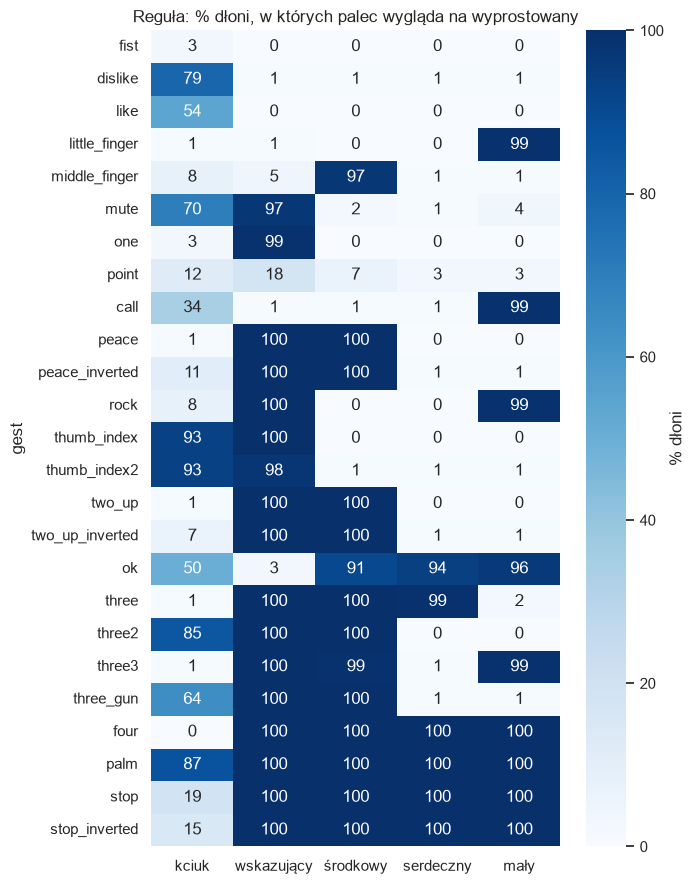

In [14]:
plt.figure(figsize=(7, 9))
sns.heatmap(check[FINGERS].rename(columns=FINGER_PL).rename_axis("gest"), annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% dłoni"})
plt.title("Reguła: % dłoni, w których palec wygląda na wyprostowany")
plt.tight_layout(); plt.savefig(FIG / "eda_mapping_check.png", dpi=150); plt.show()

### Co mówi to sprawdzenie

Reguła zgadza się z mapowaniem dla 20 z 25 gestów. Jest prymitywna (tylko 2D, stały próg kąta), więc niezgodność
to powód, żeby obejrzeć obrazy, a nie dowód błędu.

- Palec wskazujący, środkowy, serdeczny i mały są wykrywane czysto dla większości gestów. Mapowanie się zgadza dla
  `fist`, `one`, `little_finger`, `middle_finger`, `peace*`, `two_up*`, `rock`, `three`, `three3`, `four`.
- **Kciuk to trudny palec.** Często jest wyprostowany do połowy albo widoczny z boku. To on stoi za każdą
  niezgodnością poniżej.
- `point`: palec wskazujący celuje **w kamerę**, więc w 2D jest skrócony i wygląda na zgięty.
  Licznik oparty na kamerze będzie miał ten sam problem. Kandydat do odrzucenia.
- `stop`, `stop_inverted`: kciuk zwykle leży wzdłuż dłoni, więc reguła widzi 4, a nie 5.
  To, czy liczymy to jako 5, jest kwestią definicji. Grozi też myleniem z `four`.
- `mute`: kciuk jest często widoczny obok podniesionego palca wskazującego. Raczej 1, ale z szumem.
- `call`: kciuk i mały palec wyprostowane. Kciuk często widać z boku, więc reguła widzi tylko mały palec
  (1 zamiast 2).
- `ok`: kciuk i palec wskazujący tworzą kółko, trzy palce w górze. Reguła zgadza się z 3.

**Następny krok:** potwierdzić te przypadki na prawdziwych obrazach po pobraniu podzbioru obrazów.

## Podsumowanie

| Pytanie | Odpowiedź |
|---|---|
| Liczba klas | 33 gesty + no_gesture w źródle, 6 klas docelowych (0-5 palców) po mapowaniu |
| Balans | Gesty źródłowe zbalansowane. Klasy docelowe niezbalansowane, bo klasa 4 ma jeden gest źródłowy |
| Jakość danych | Podziały rozłączne po osobach. 27 ramek lekko wychodzi poza krawędź obrazu, 346 obrazów bez metadanych, 1.9% dłoni bez landmarków. Dłonie są małe (mediana 2.4% kadru) |
| Mapowanie | Reguła zgadza się dla 20 z 25 gestów. Gesty zależne od kciuka (`point`, `call`, `mute`, `stop*`) wymagają sprawdzenia na obrazach |